# Modelo final: predecir la *energy* de una canción

**Dataset:** Top 100 canciones más reproducidas en Spotify (100 filas, 14 columnas; cada fila es una canción o versión).
**Problema:** regresión. Queremos predecir `energy` (0 a 1) a partir de las demás características de audio.

Este notebook va de arriba a abajo: limpieza, split train/val/test, baseline, modelos, elección por validación, test (una sola vez) e importancia de variables.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

SEED = 42
Path('../figures').mkdir(exist_ok=True)
df = pd.read_csv(Path('..') / 'data' / 'top 100 streamed_songs.csv')
print(df.shape)

(100, 14)


## 1. Limpieza: quitar canciones repetidas

En el EDA vimos que hay canciones repetidas (mismo `id`, por remixes o ediciones). Si una misma canción cae en train y en test, el modelo "ya la vio" y el score sale inflado (fuga de información). Por eso dejamos una sola fila por `id`.

In [2]:
print('IDs repetidos:', df['id'].duplicated().sum())
df = df.drop_duplicates(subset='id').reset_index(drop=True)
print('Filas después de limpiar:', len(df))

IDs repetidos: 14
Filas después de limpiar: 86


## 2. Definir y y X

- **y = `energy`** (número entre 0 y 1) → es un valor continuo, por eso es **regresión**.
- **X** = las otras 11 variables numéricas de audio. Quitamos `id` y `name` (identificadores, no describen el sonido).
- No hay fuga: ninguna columna de X se calcula a partir de `energy`. (`loudness` está muy relacionada con `energy`, pero es una medida de audio distinta, no una versión de ella.)

In [3]:
y = df['energy']
X = df.drop(columns=['id', 'name', 'energy'])
print('Variables en X:', list(X.columns))

Variables en X: ['duration', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'danceability']


## 3. Split train / validación / test (60 / 20 / 20)

- **Train:** para que el modelo aprenda.
- **Validación:** para comparar modelos y elegir el mejor.
- **Test:** se usa **una sola vez**, al final, solo con el modelo elegido.

In [4]:
X_tv, X_test, y_tv, y_test = train_test_split(X, y, test_size=0.20, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_tv, y_tv, test_size=0.25, random_state=SEED)
print(f'train={len(X_train)}  val={len(X_val)}  test={len(X_test)}')

train=51  val=17  test=18


## 4. Baseline y modelos

**Métrica: MAE** (error absoluto promedio), en las mismas unidades que `energy`. Un MAE de 0.10 significa que el modelo se equivoca en promedio por 0.10 puntos de energy (en una escala de 0 a 1). También reportamos R².

El **baseline** siempre predice el promedio de energy del train. Cualquier modelo útil debe superarlo.

In [5]:
modelos = {
    'Baseline (promedio)':        DummyRegressor(strategy='mean'),
    'Regresión lineal':           make_pipeline(StandardScaler(), LinearRegression()),
    'KNN (k = 7)':                make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=7)),
    'Árbol de decisión (depth=3)': DecisionTreeRegressor(max_depth=3, random_state=SEED),
    'Random Forest (depth=4)':    RandomForestRegressor(n_estimators=200, max_depth=4, random_state=SEED),
}

filas = []
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    filas.append({
        'Modelo': nombre,
        'MAE train': mean_absolute_error(y_train, modelo.predict(X_train)),
        'MAE val':   mean_absolute_error(y_val,   modelo.predict(X_val)),
        'R2 val':    r2_score(y_val, modelo.predict(X_val)),
    })

resultados = pd.DataFrame(filas).set_index('Modelo').round(3)
resultados

,MAE train,MAE val,R2 val
Modelo,,,
Baseline (promedio),0.125,0.175,-0.014
Regresión lineal,0.051,0.095,0.735
KNN (k = 7),0.075,0.123,0.505
Árbol de decisión (depth=3),0.043,0.120,0.477
Random Forest (depth=4),0.033,0.130,0.457


## 5. Elegir el mejor por validación y revisar overfitting

Elegimos el modelo con **menor MAE en validación** (no en train, no en test). Overfitting = el error en train es mucho menor que en validación.

In [6]:
mejor = resultados['MAE val'].idxmin()
resultados['Brecha (val - train)'] = (resultados['MAE val'] - resultados['MAE train']).round(3)
print('Mejor modelo por validación:', mejor)
resultados

Mejor modelo por validación: Regresión lineal


,MAE train,MAE val,R2 val,Brecha (val - train)
Modelo,,,,
Baseline (promedio),0.125,0.175,-0.014,0.050
Regresión lineal,0.051,0.095,0.735,0.044
KNN (k = 7),0.075,0.123,0.505,0.048
Árbol de decisión (depth=3),0.043,0.120,0.477,0.077
Random Forest (depth=4),0.033,0.130,0.457,0.097


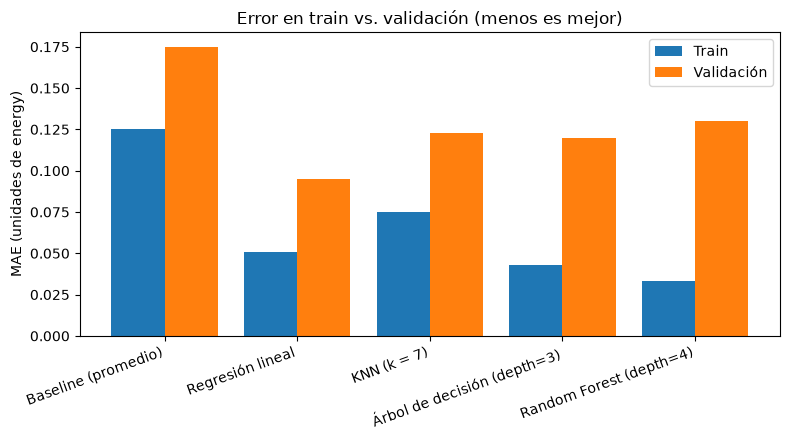

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pos = np.arange(len(resultados))
ax.bar(pos - 0.2, resultados['MAE train'], width=0.4, label='Train')
ax.bar(pos + 0.2, resultados['MAE val'],   width=0.4, label='Validación')
ax.set_xticks(pos, labels=resultados.index, rotation=20, ha='right')
ax.set_ylabel('MAE (unidades de energy)')
ax.set_title('Error en train vs. validación (menos es mejor)')
ax.legend()
fig.tight_layout()
fig.savefig('../figures/mae_train_val.png', dpi=200)
plt.show()

## 6. Score en test (una sola vez)

Entrenamos el modelo elegido con el **train** y lo evaluamos en el **test**. No volvemos a cambiar nada después de ver este número.

In [8]:
modelo_final = modelos[mejor]
pred_test = modelo_final.predict(X_test)
mae_test = mean_absolute_error(y_test, pred_test)
r2_test = r2_score(y_test, pred_test)

mae_base_test = mean_absolute_error(y_test, modelos['Baseline (promedio)'].predict(X_test))
print(f'{mejor}: MAE test = {mae_test:.3f}   R2 test = {r2_test:.2f}')
print(f'(Referencia: el baseline tendría MAE test = {mae_base_test:.3f})')

Regresión lineal: MAE test = 0.105   R2 test = 0.16
(Referencia: el baseline tendría MAE test = 0.130)


In [9]:
resultados['MAE test'] = np.nan
resultados.loc[mejor, 'MAE test'] = round(mae_test, 3)
resultados.to_csv('../figures/tabla_resultados.csv')
resultados

,MAE train,MAE val,R2 val,Brecha (val - train),MAE test
Modelo,,,,,
Baseline (promedio),0.125,0.175,-0.014,0.050,NaN
Regresión lineal,0.051,0.095,0.735,0.044,0.105
KNN (k = 7),0.075,0.123,0.505,0.048,NaN
Árbol de decisión (depth=3),0.043,0.120,0.477,0.077,NaN
Random Forest (depth=4),0.033,0.130,0.457,0.097,NaN


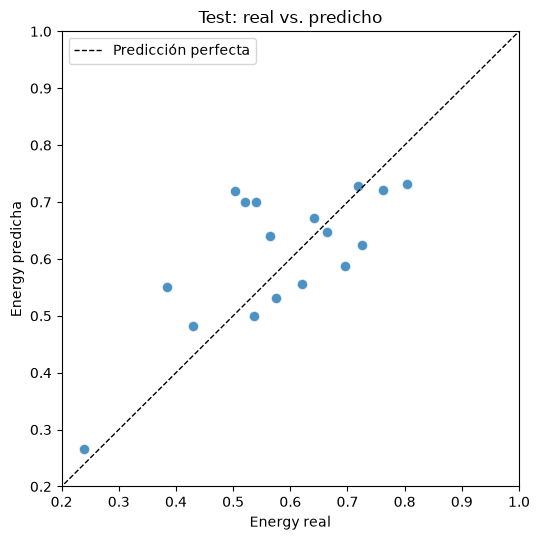

In [10]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(y_test, pred_test, s=60, alpha=0.8, edgecolors='white')
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Predicción perfecta')
ax.set_xlim(0.2, 1); ax.set_ylim(0.2, 1)
ax.set_xlabel('Energy real'); ax.set_ylabel('Energy predicha')
ax.set_title('Test: real vs. predicho')
ax.legend()
fig.tight_layout()
fig.savefig('../figures/test_real_vs_predicho.png', dpi=200)
plt.show()

## 7. Importancia de variables

Como el modelo elegido es una regresión lineal con variables estandarizadas, sus **coeficientes** indican cuánto cambia la energy predicha cuando una variable sube una desviación estándar (positivo = sube la energy, negativo = baja).

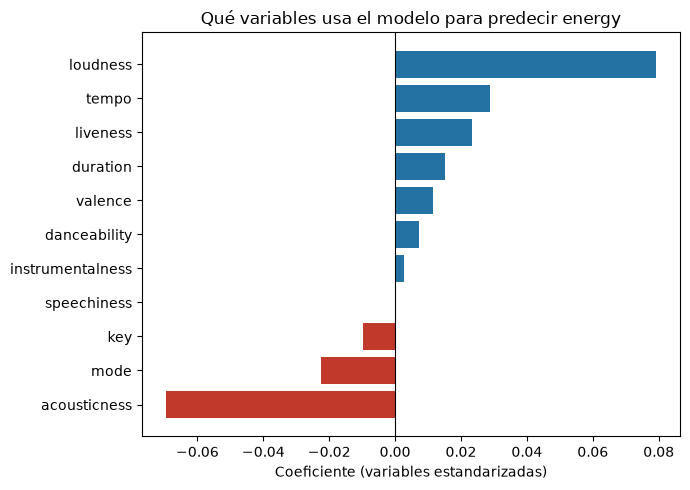

loudness            0.079
acousticness       -0.069
tempo               0.029
liveness            0.023
mode               -0.023
duration            0.015
valence             0.012
key                -0.010
danceability        0.007
instrumentalness    0.003
speechiness        -0.000
dtype: float64

In [11]:
coefs = pd.Series(modelo_final[-1].coef_, index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 5))
colores = ['#c0392b' if v < 0 else '#2471a3' for v in coefs]
ax.barh(coefs.index, coefs.values, color=colores)
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Coeficiente (variables estandarizadas)')
ax.set_title('Qué variables usa el modelo para predecir energy')
fig.tight_layout()
fig.savefig('../figures/importancia_variables.png', dpi=200)
plt.show()
coefs.sort_values(key=abs, ascending=False).round(3)

### Chequeo extra: ¿un Random Forest dice lo mismo?

In [12]:
rf = modelos['Random Forest (depth=4)']
imp_rf = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
imp_rf.round(3)

loudness            0.665
acousticness        0.198
duration            0.026
speechiness         0.023
valence             0.021
liveness            0.017
tempo               0.015
danceability        0.013
key                 0.010
instrumentalness    0.009
mode                0.004
dtype: float64

## 8. Conclusión

- **¿Sirve el modelo?** Parcialmente. La regresión lineal (MAE test = 0.105) comete ~19% menos error que adivinar el promedio (0.130), pero un error de 0.10 en una escala de 0 a 1 sigue siendo grande.
- **Variables:** `loudness` (+) y `acousticness` (-) pesan más, igual que en el EDA (r = +0.67 y -0.58). Un Random Forest como chequeo también las pone arriba.
- **Overfitting:** el árbol y el Random Forest memorizan el train (MAE 0.03-0.04) pero fallan en validación (0.12-0.13). Con solo 51 canciones de entrenamiento, el modelo simple generaliza mejor.
- **Limitación importante:** con 86 canciones, validación (17) y test (18) son muy chicos. El R² pasó de 0.73 en validación a 0.16 en test, así que los números son orientativos.
- **Qué haríamos diferente:** más canciones, validación cruzada y más variables (género, año).